In [ ]:
# data process
"""
Stores NN-ready (coordinates, valence, target, group_id).
parameters: theta_delta=0.5, alpha_delta=0.9,
regularization delta=2.5e-5, softmin alpha=50.
fitted approximate Gaussian for valences, seed 42, fixed-fan default (or optional Delaunay one-ring extraction), CG tolerance and validity filters.
"""
from pathlib import Path
import numpy as np
from scipy.optimize import minimize
from scipy.spatial import Delaunay, QhullError
from scipy.special import logsumexp

SEED = 42
N_PATCHES = 60000              
THETA_DELTA = 0.5
ALPHA_DELTA = 0.9
DELTA = 2.5e-5
SOFTMIN_ALPHA = 50.0
CONNECTIVITY = "fan"        # "fan" preserves n; "delaunay triangulation" may change n
OUTPUT = Path("vasonet_dataset.npz")
rng = np.random.default_rng(SEED)

# n --Gaussian (u,segame^2) normal distribution
allowed_n = np.arange(3, 10) #3-9, not include 10
mu, sigma = 5.43, 1.62
valence_probs = np.exp(-0.5 * ((allowed_n - mu) / sigma) ** 2)
valence_probs /= valence_probs.sum()


def generate_ring(n):
    theta = 2 * np.pi * np.arange(n) / n
    theta += rng.uniform(-THETA_DELTA * 2 * np.pi / n,
                          THETA_DELTA * 2 * np.pi / n, size=n)
    theta += rng.uniform(-np.pi / 2, np.pi / 2)
    radial_perturbation = rng.uniform(-ALPHA_DELTA, ALPHA_DELTA, size=n)
    radius = 1.0 - radial_perturbation
    return np.column_stack([radius * np.cos(theta), radius * np.sin(theta)])


def get_one_ring(proposed_ring):
    """center's actual CCW one-ring. None means invalid/non-interior patch."""
    if CONNECTIVITY == "fan":
        ring = proposed_ring
    else:
        points = np.vstack([np.zeros((1, 2)), proposed_ring])
        try:
            simplices = Delaunay(points).simplices
        except QhullError:
            return None
        center_faces = simplices[np.any(simplices == 0, axis=1)]
        neighbors = np.unique(center_faces[center_faces != 0])
        if len(neighbors) < 3 or len(center_faces) != len(neighbors):
            return None  # center must be strictly interior
        ring = points[neighbors]
        ring = ring[np.argsort(np.arctan2(ring[:, 1], ring[:, 0]))]

    next_ring = np.roll(ring, -1, axis=0)
    signed_area2 = ring[:, 0] * next_ring[:, 1] - ring[:, 1] * next_ring[:, 0]
    if np.any(signed_area2 <= 1e-12):
        return None  # invalid orientation or center outside star kernel
    return ring


def quality_and_gradient(center, ring):
    """Regularized mean ratio and its analytic derivatives"""
    u = ring - center
    v = np.roll(u, -1, axis=0)

    # S=[u, (2v-u)/sqrt(3)].
    norm2 = np.sum(u*u, axis=1) + np.sum((2*v-u)**2, axis=1) / 3.0
    det = (2.0 / np.sqrt(3.0)) * (u[:, 0]*v[:, 1] - u[:, 1]*v[:, 0])
    root = np.sqrt(det**2 + 4*DELTA**2)
    numerator = np.where(det >= 0, det+root, 4*DELTA**2/(root-det))
    q = numerator / norm2

    d_norm2 = -(4.0/3.0) * (u+v)
    a = ring
    b = np.roll(ring, -1, axis=0)
    d_det = (2.0 / np.sqrt(3.0)) * np.column_stack((a[:, 1]-b[:, 1], b[:, 0]-a[:, 0]))
    d_numerator = (1 + det/root)[:, None] * d_det
    d_q = d_numerator/norm2[:, None] - (q/norm2)[:, None] * d_norm2
    return q, det, d_q


def objective(center, ring):
    """Minimize the negative LogSumExp smooth minimum, Eq. 10."""
    q, _, d_q = quality_and_gradient(center, ring)
    z = -SOFTMIN_ALPHA * q
    log_z = logsumexp(z)
    weights = np.exp(z - log_z)
    loss = log_z / SOFTMIN_ALPHA
    gradient = -(weights[:, None] * d_q).sum(axis=0)
    return loss, gradient


def optimize_center(ring):
    center0 = np.zeros(2)
    result = minimize(objective, center0, args=(ring,), method="CG", jac=True,
                      options={"gtol": 1e-7, "maxiter": 300})

    center = result.x
    q, det, _ = quality_and_gradient(center, ring)
    initial_loss = objective(center0, ring)[0]
    final_loss = objective(center, ring)[0]
    return center


def normalize_patch(ring, center):
    lower = ring.min(axis=0)
    upper = ring.max(axis=0)
    scale = (upper-lower).max()
    return (ring-lower)/scale, (center-lower)/scale


def create_dataset(count):
    coordinates, valence, targets, group_id = [], [], [], []
    quality_before, quality_after = [], []
    attempted = 0

    for sample_id in range(count):
        n = int(rng.choice(allowed_n, p=valence_probs))
        # Keep this sampled n fixed while retrying invalid geometries.
        for _ in range(500):
            attempted += 1
            ring = get_one_ring(generate_ring(n))
            if ring is None:
                continue
            center = optimize_center(ring)
            if center is not None:
                break
        else:
            raise RuntimeError(f"Failed to optimize a valence-{n} ring")

        q_before = quality_and_gradient(np.zeros(2), ring)[0].min()
        q_after = quality_and_gradient(center, ring)[0].min()
        ring, center = normalize_patch(ring, center)
        actual_n = len(ring)

        for k in range(actual_n):
            reordered = np.roll(ring, k, axis=0)
            padded = np.zeros((9, 2), dtype=np.float32)
            padded[:actual_n] = reordered
            coordinates.append(padded.reshape(18))
            valence.append(actual_n)
            targets.append(center.astype(np.float32))
            group_id.append(sample_id)
            quality_before.append(q_before)
            quality_after.append(q_after)

    np.savez_compressed(
        OUTPUT,
        coordinates=np.asarray(coordinates, dtype=np.float32),
        valence=np.asarray(valence, dtype=np.float32).reshape(-1, 1),
        target=np.asarray(targets, dtype=np.float32),
        group_id=np.asarray(group_id, dtype=np.int32),
        min_quality_before=np.asarray(quality_before, dtype=np.float32),
        min_quality_after=np.asarray(quality_after, dtype=np.float32),
    )
    print(f"Saved {count:,} patches / {len(valence):,} samples to {OUTPUT} (attempts: {attempted:,})")


if __name__ == "__main__":
    create_dataset(N_PATCHES)

Saved 60,000 patches / 331,275 samples to vasonet_dataset.npz (attempts: 62,937)


In [4]:
# model process
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

class VASONet(nn.Module):
    @staticmethod
    def init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)

    def __init__(self):
        super().__init__()
        self.geo_mlp = nn.Sequential(
            nn.Linear(18, 320),nn.ReLU(),nn.Dropout(0.0064)
        )

        self.topo_mlp = nn.Sequential(
            nn.Linear(1, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(352, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 2)
        )
        self.apply(self.init_weights)

    def forward(self, coordinates, valence):
        x = coordinates.reshape(-1, 18).float()
        n = valence.reshape(-1, 1).float()

        hg = self.geo_mlp(x)
        ht = self.topo_mlp(n)

        h = torch.cat([hg, ht], dim=1)
        return self.decoder(h)

Valence_MLP = VASONet().to(device)
# setting
loss = nn.MSELoss()
learning_rates = 6.5e-4
epochs = 200
batch_size = 64
optimizer = torch.optim.Adam( Valence_MLP.parameters(), lr=learning_rates, betas=(0.9, 0.999) )
lr_rates = torch.optim.lr_scheduler.ExponentialLR( optimizer, gamma=0.916 )


print(Valence_MLP)


Using mps device
VASONet(
  (geo_mlp): Sequential(
    (0): Linear(in_features=18, out_features=320, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0064, inplace=False)
  )
  (topo_mlp): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=32, bias=True)
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=352, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.033, inplace=False)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.033, inplace=False)
    (6): Linear(in_features=512, out_features=512, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.033, inplace=False)
    (9): Linear(in_features=512, out_features=2, bias=True)
  )
)


In [5]:
# train process
with np.load(OUTPUT) as data:
    coordinates = torch.from_numpy(data["coordinates"])
    valence = torch.from_numpy(data["valence"])
    targets = torch.from_numpy(data["target"])
    group_id = torch.from_numpy(data["group_id"])

# Split patches 70% / 20% / 10%, keeping cyclic reorderings together.
generator = torch.Generator().manual_seed(SEED)
groups = torch.unique(group_id)
groups = groups[torch.randperm(len(groups), generator=generator)]
n_train = int(0.7 * len(groups))
n_val = int(0.2 * len(groups))
train_mask = torch.isin(group_id, groups[:n_train])
val_mask = torch.isin(group_id, groups[n_train:n_train + n_val])
test_mask = torch.isin(group_id, groups[n_train + n_val:])

train_dataset = TensorDataset(coordinates[train_mask], valence[train_mask], targets[train_mask])
val_dataset = TensorDataset(coordinates[val_mask], valence[val_mask], targets[val_mask])
test_dataset = TensorDataset(coordinates[test_mask], valence[test_mask], targets[test_mask])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Samples: train={len(train_dataset):,}, val={len(val_dataset):,}, test={len(test_dataset):,}")


def evaluate_mse(loader):
    Valence_MLP.eval()
    total_loss = 0.0
    with torch.no_grad():
        for coordinates_batch, valence_batch, target_batch in loader:
            coordinates_batch = coordinates_batch.to(device)
            valence_batch = valence_batch.to(device)
            target_batch = target_batch.to(device)
            prediction = Valence_MLP(coordinates_batch, valence_batch)
            total_loss += loss(prediction, target_batch).item() * len(target_batch)
    return total_loss / len(loader.dataset)


history = {"train": [], "val": [], "test": []}
for epoch in range(1, epochs + 1):
    Valence_MLP.train()
    total_train_loss = 0.0
    for coordinates_batch, valence_batch, target_batch in train_loader:
        coordinates_batch = coordinates_batch.to(device)
        valence_batch = valence_batch.to(device)
        target_batch = target_batch.to(device)

        optimizer.zero_grad(set_to_none=True)
        prediction = Valence_MLP(coordinates_batch, valence_batch)
        batch_loss = loss(prediction, target_batch)
        batch_loss.backward()
        optimizer.step()
        total_train_loss += batch_loss.item() * len(target_batch)

    train_mse = total_train_loss / len(train_dataset)
    val_mse = evaluate_mse(val_loader)
    test_mse = evaluate_mse(test_loader)
    history["train"].append(train_mse)
    history["val"].append(val_mse)
    history["test"].append(test_mse)
    print(
        f"Epoch {epoch:03d}/{epochs} | Train MSE: {train_mse:.8f} | "
        f"Val MSE: {val_mse:.8f} | Test MSE: {test_mse:.8f}",
        flush=True,
    )
    lr_rates.step()

# Final-epoch weights. Reload after defining VASONet:
# Valence_MLP.load_state_dict(torch.load("MLP.pt", map_location=device, weights_only=True))
torch.save(Valence_MLP.state_dict(), "MLP.pt")
print("Saved final model weights to MLP.pt")


Samples: train=232,235, val=66,034, test=33,006
Epoch 001/200 | Train MSE: 0.00477334 | Val MSE: 0.00340833 | Test MSE: 0.00339889
Epoch 002/200 | Train MSE: 0.00284542 | Val MSE: 0.00218609 | Test MSE: 0.00219066
Epoch 003/200 | Train MSE: 0.00227910 | Val MSE: 0.00194698 | Test MSE: 0.00197729
Epoch 004/200 | Train MSE: 0.00195664 | Val MSE: 0.00163041 | Test MSE: 0.00164197
Epoch 005/200 | Train MSE: 0.00172435 | Val MSE: 0.00185941 | Test MSE: 0.00185853
Epoch 006/200 | Train MSE: 0.00155273 | Val MSE: 0.00141719 | Test MSE: 0.00141494
Epoch 007/200 | Train MSE: 0.00142978 | Val MSE: 0.00130303 | Test MSE: 0.00130296
Epoch 008/200 | Train MSE: 0.00131737 | Val MSE: 0.00116209 | Test MSE: 0.00117866
Epoch 009/200 | Train MSE: 0.00122969 | Val MSE: 0.00112243 | Test MSE: 0.00112982
Epoch 010/200 | Train MSE: 0.00115813 | Val MSE: 0.00113457 | Test MSE: 0.00112615
Epoch 011/200 | Train MSE: 0.00108684 | Val MSE: 0.00102235 | Test MSE: 0.00103007
Epoch 012/200 | Train MSE: 0.00103731 |

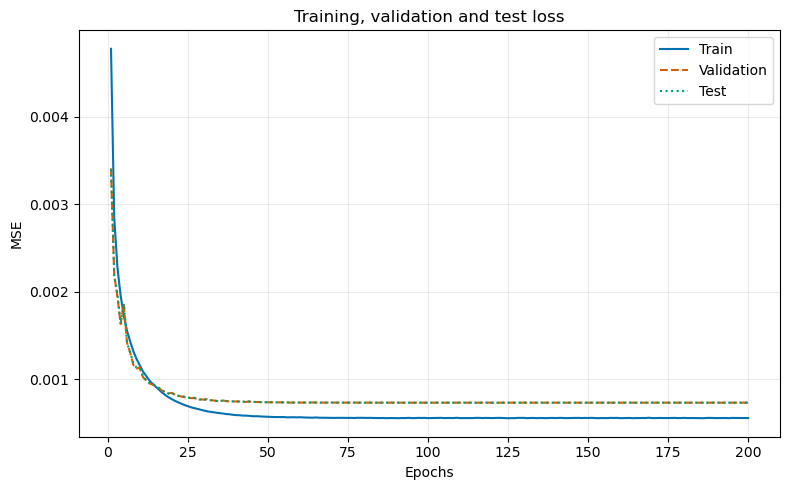

In [6]:
# train / validation / test loss visualization
import matplotlib.pyplot as plt

# Train MSE is averaged over training batches (dropout on).
# Validation and test MSE use eval mode; test loss is for reporting only.
epoch_axis = range(1, len(history["train"]) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_axis, history["train"], label="Train", color="#0072B2", linestyle="-")
ax.plot(epoch_axis, history["val"], label="Validation", color="#D55E00", linestyle="--")
ax.plot(epoch_axis, history["test"], label="Test", color="#009E73", linestyle=":")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_title("Training, validation and test loss")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
